# Image similarity analysis - pairwise comparison (DVI1)

This notebook compares the 16 images of `DVI1` **with each other** using colour
features and shows the most similar pairs.

* **Colour histogram** - one 256-bin histogram per B, G, R channel, compared with the Bhattacharyya distance.
* **Dominant colours** - K-Means palette (clusters covering more than 5 % of the pixels), compared with a weighted nearest-colour distance.
* **Global metric** - average of both distances after normalising each one to [0, 1].

The helper functions live in [`features.py`](features.py) and are shared with `image_retrieval.ipynb`.

In [1]:
import os
import random

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from features import (calculate_color_histogram, category, dominant_color_distance,
                      extract_features, find_dominant_colors, histogram_distance,
                      list_images, load_json, rank, save_json)

DATABASE_DIR = "DVI1"  # 16 reference images, 4 per category
QUERY_DIR = "DVI2"     # 1 query image per category

## Step 1 - Load the images

In [2]:
image_paths = list_images(DATABASE_DIR)
names = [os.path.basename(p) for p in image_paths]
print(len(names), "images:", names)

16 images: ['1472.jpg', '1479.jpg', '1484.jpg', '1488.jpg', '3402.jpg', '3408.jpg', '3409.jpg', '3448.jpg', '8185.jpg', '8186.jpg', '8189.jpg', '8200.jpg', '8965.jpg', '8980.jpg', '8982.jpg', '8990.jpg']


## Step 2 - Colour histograms

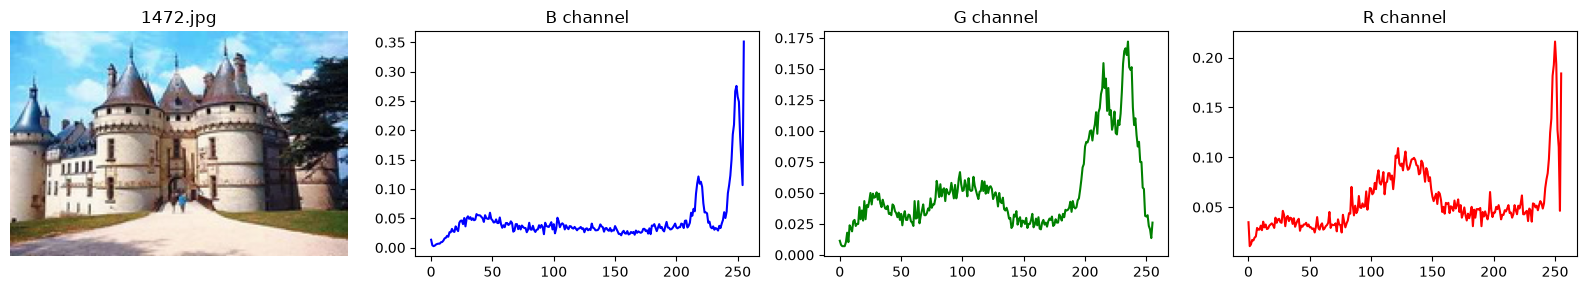

In [3]:
image_histograms = {n: calculate_color_histogram(p) for n, p in zip(names, image_paths)}

example = names[0]
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
axes[0].imshow(Image.open(image_paths[0])); axes[0].set_title(example); axes[0].axis("off")
for ax, channel in zip(axes[1:], ("b", "g", "r")):
    ax.plot(image_histograms[example][channel], color=channel)
    ax.set_title(f"{channel.upper()} channel")
plt.tight_layout()
plt.show()

## Step 3 - Dominant colours (K-Means, k = 20, threshold 5 %)

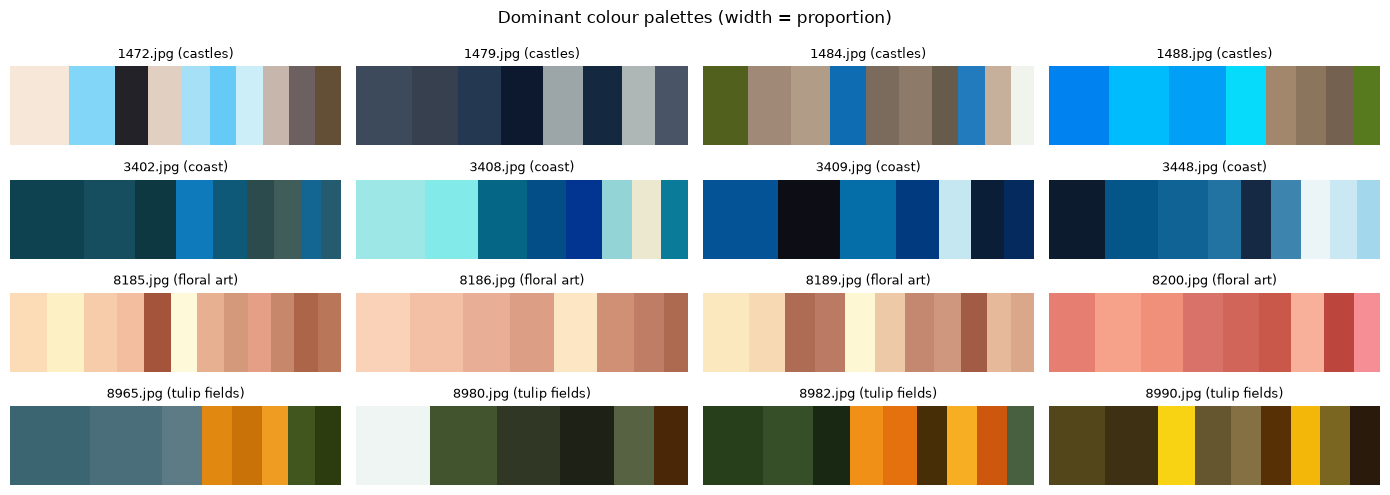

In [4]:
image_dominant_colors = {n: find_dominant_colors(p) for n, p in zip(names, image_paths)}

fig, axes = plt.subplots(4, 4, figsize=(14, 5))
for ax, name in zip(axes.flat, names):
    dom = image_dominant_colors[name]
    widths = np.round(np.array(dom["weights"]) * 100).astype(int)
    bar = np.repeat(np.array(dom["colors"])[None].astype(np.uint8), np.maximum(widths, 1), axis=1)
    ax.imshow(bar, aspect="auto")
    ax.set_title(f"{name} ({category(name)})", fontsize=9)
    ax.axis("off")
plt.suptitle("Dominant colour palettes (width = proportion)")
plt.tight_layout()
plt.show()

## Step 4 - Pairwise distances

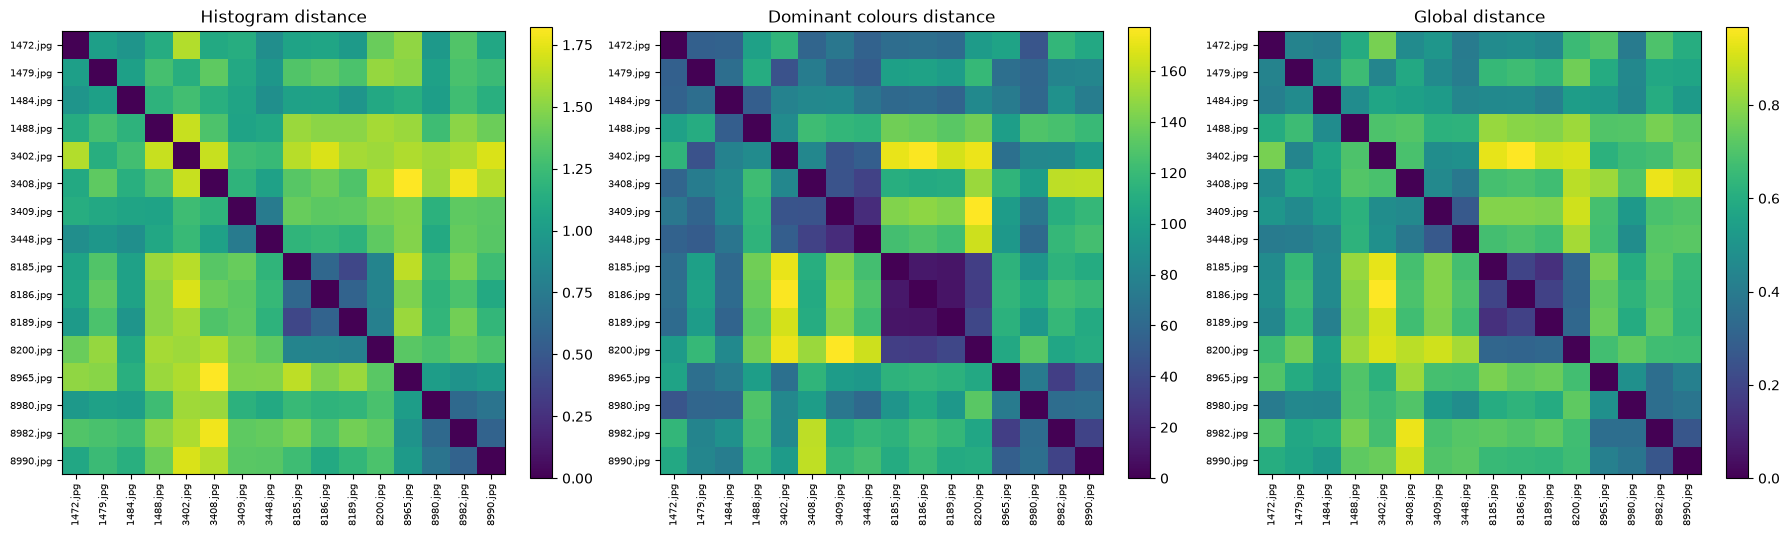

In [5]:
n = len(names)
H = np.zeros((n, n))
C = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        H[i, j] = H[j, i] = histogram_distance(image_histograms[names[i]], image_histograms[names[j]])
        C[i, j] = C[j, i] = dominant_color_distance(image_dominant_colors[names[i]], image_dominant_colors[names[j]])
G = 0.5 * H / H.max() + 0.5 * C / C.max()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (title, M) in zip(axes, (("Histogram", H), ("Dominant colours", C), ("Global", G))):
    im = ax.imshow(M, cmap="viridis")
    ax.set_xticks(range(n), names, rotation=90, fontsize=7)
    ax.set_yticks(range(n), names, fontsize=7)
    ax.set_title(f"{title} distance")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

The block structure along the diagonal shows that images of the same category (4 consecutive images) are closer to each other.

## Step 5 - Most similar pairs

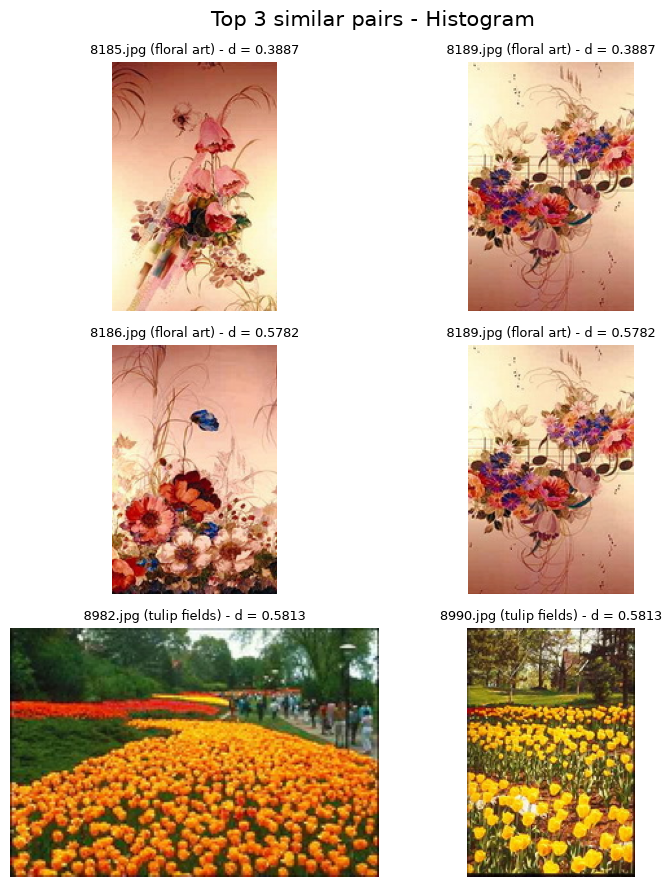

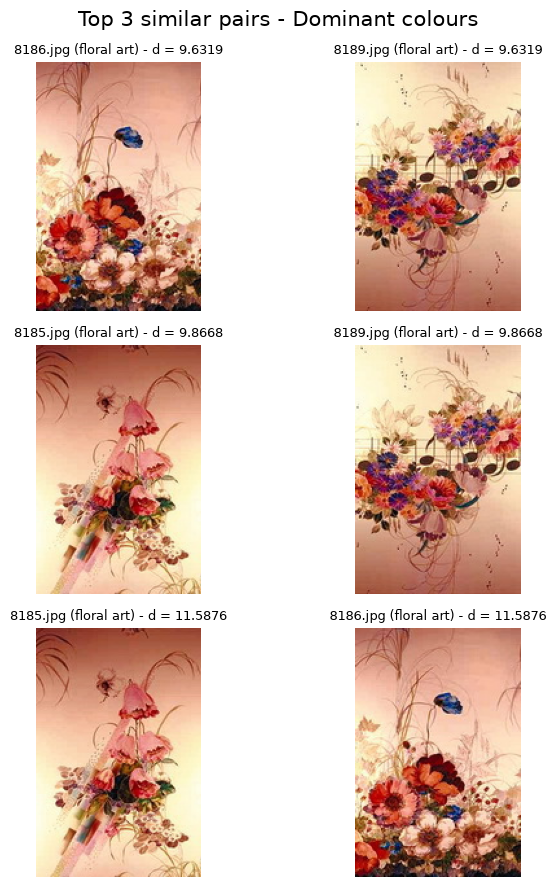

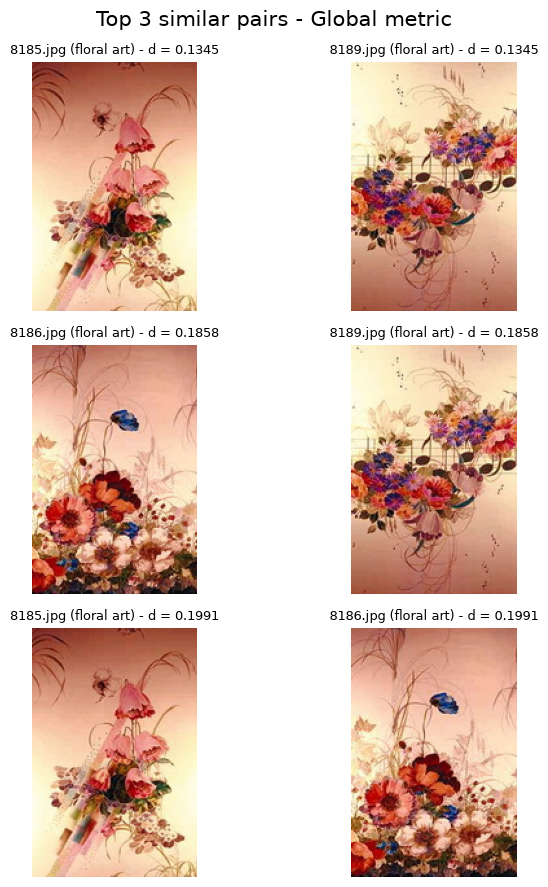

In [6]:
def top_pairs(M, k=3):
    iu = np.triu_indices(len(M), 1)
    order = np.argsort(M[iu])[:k]
    return [((names[iu[0][o]], names[iu[1][o]]), M[iu][o]) for o in order]


def plot_similar_pairs(pairs, title):
    fig, axes = plt.subplots(len(pairs), 2, figsize=(8, 3 * len(pairs)))
    fig.suptitle(title, fontsize=15)
    for row, ((n1, n2), score) in zip(axes, pairs):
        for ax, name in zip(row, (n1, n2)):
            ax.imshow(Image.open(os.path.join(DATABASE_DIR, name)))
            ax.set_title(f"{name} ({category(name)}) - d = {score:.4f}", fontsize=9)
            ax.axis("off")
    plt.tight_layout()
    plt.show()


for title, M in (("Histogram", H), ("Dominant colours", C), ("Global metric", G)):
    plot_similar_pairs(top_pairs(M), f"Top 3 similar pairs - {title}")